<a href="https://colab.research.google.com/github/drishtisharma14052007-eng/PDF-Assistant-RAG/blob/dev/F1ChampPredictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***F1ChampPredictor***

F1 Champion Classification Using Machine Learning


# **LOADING DATASET**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn


from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/F1Drivers_Dataset.csv')


df=pd.DataFrame(data)
print(df.head())
print(df.columns)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
              Driver     Nationality                         Seasons  \
0        Carlo Abate           Italy                    [1962, 1963]   
1   George Abecassis  United Kingdom                    [1951, 1952]   
2      Kenny Acheson  United Kingdom                    [1983, 1985]   
3  Andrea de Adamich           Italy  [1968, 1970, 1971, 1972, 1973]   
4     Philippe Adams         Belgium                          [1994]   

   Championships  Race_Entries  Race_Starts  Pole_Positions  Race_Wins  \
0            0.0           3.0          0.0             0.0        0.0   
1            0.0           2.0          2.0             0.0        0.0   
2            0.0          10.0          3.0             0.0        0.0   
3            0.0          36.0         30.0             0.0        0.0   
4            0.0           2.0          2.0             0.0        0

# **DATA PREPROCESSING**

In [ ]:
print(df.info())
print(df.shape)
print(df.isnull().sum())
#deleting feature chamionship year
del df["Championship Years"]
print(df.columns)
df['Seasons'] = df['Seasons'].apply(lambda x: len(eval(x)) if isinstance(x, str) and x.startswith('[') else 0)
print(df['Seasons'])




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 868 entries, 0 to 867
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Driver              868 non-null    object 
 1   Nationality         868 non-null    object 
 2   Seasons             868 non-null    object 
 3   Championships       868 non-null    float64
 4   Race_Entries        868 non-null    float64
 5   Race_Starts         868 non-null    float64
 6   Pole_Positions      868 non-null    float64
 7   Race_Wins           868 non-null    float64
 8   Podiums             868 non-null    float64
 9   Fastest_Laps        868 non-null    float64
 10  Points              868 non-null    float64
 11  Active              868 non-null    bool   
 12  Championship Years  34 non-null     object 
 13  Decade              868 non-null    int64  
 14  Pole_Rate           868 non-null    float64
 15  Start_Rate          868 non-null    float64
 16  Win_Rate

# CORRELATION

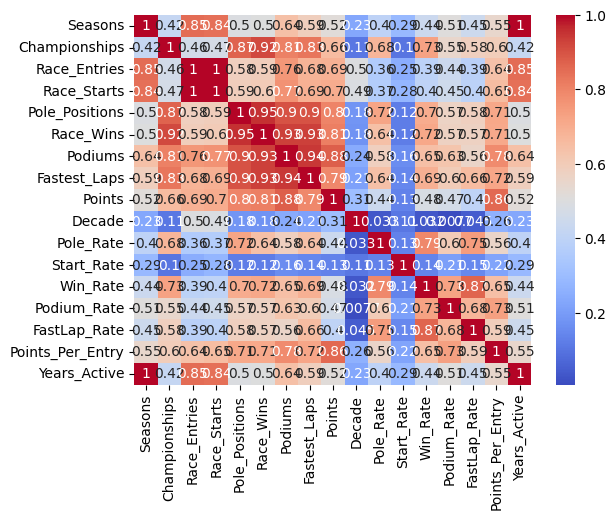

Championships       1.000000
Race_Wins           0.915247
Pole_Positions      0.869342
Fastest_Laps        0.829641
Podiums             0.808274
Win_Rate            0.730320
Pole_Rate           0.675121
Points              0.655567
Points_Per_Entry    0.596426
FastLap_Rate        0.583335
Podium_Rate         0.549377
Race_Starts         0.471073
Race_Entries        0.462985
Seasons             0.419484
Years_Active        0.419484
Decade              0.105263
Start_Rate          0.101046
Name: Championships, dtype: float64


In [ ]:
numeric_df=df.select_dtypes(include=['int64','float64'])

corr_matrix=numeric_df.corr()
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm')
plt.show()
champ_corr=corr_matrix['Championships'].sort_values(ascending=False)
print(champ_corr)

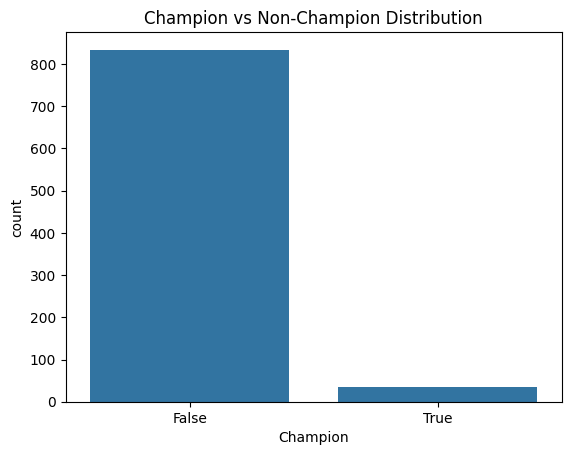

In [ ]:
sns.countplot(x='Champion', data=df)
plt.title('Champion vs Non-Champion Distribution')
plt.show()


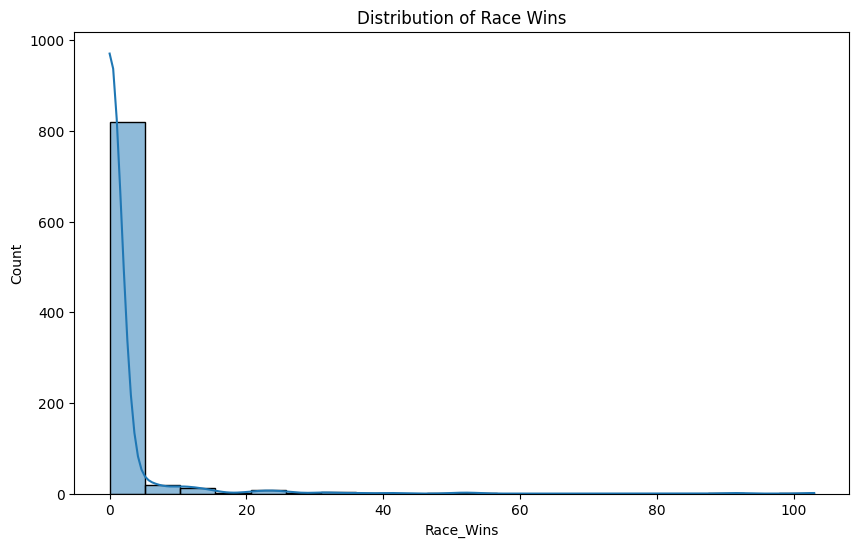

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(df['Race_Wins'], bins=20, kde=True)
plt.title('Distribution of Race Wins')
plt.show()


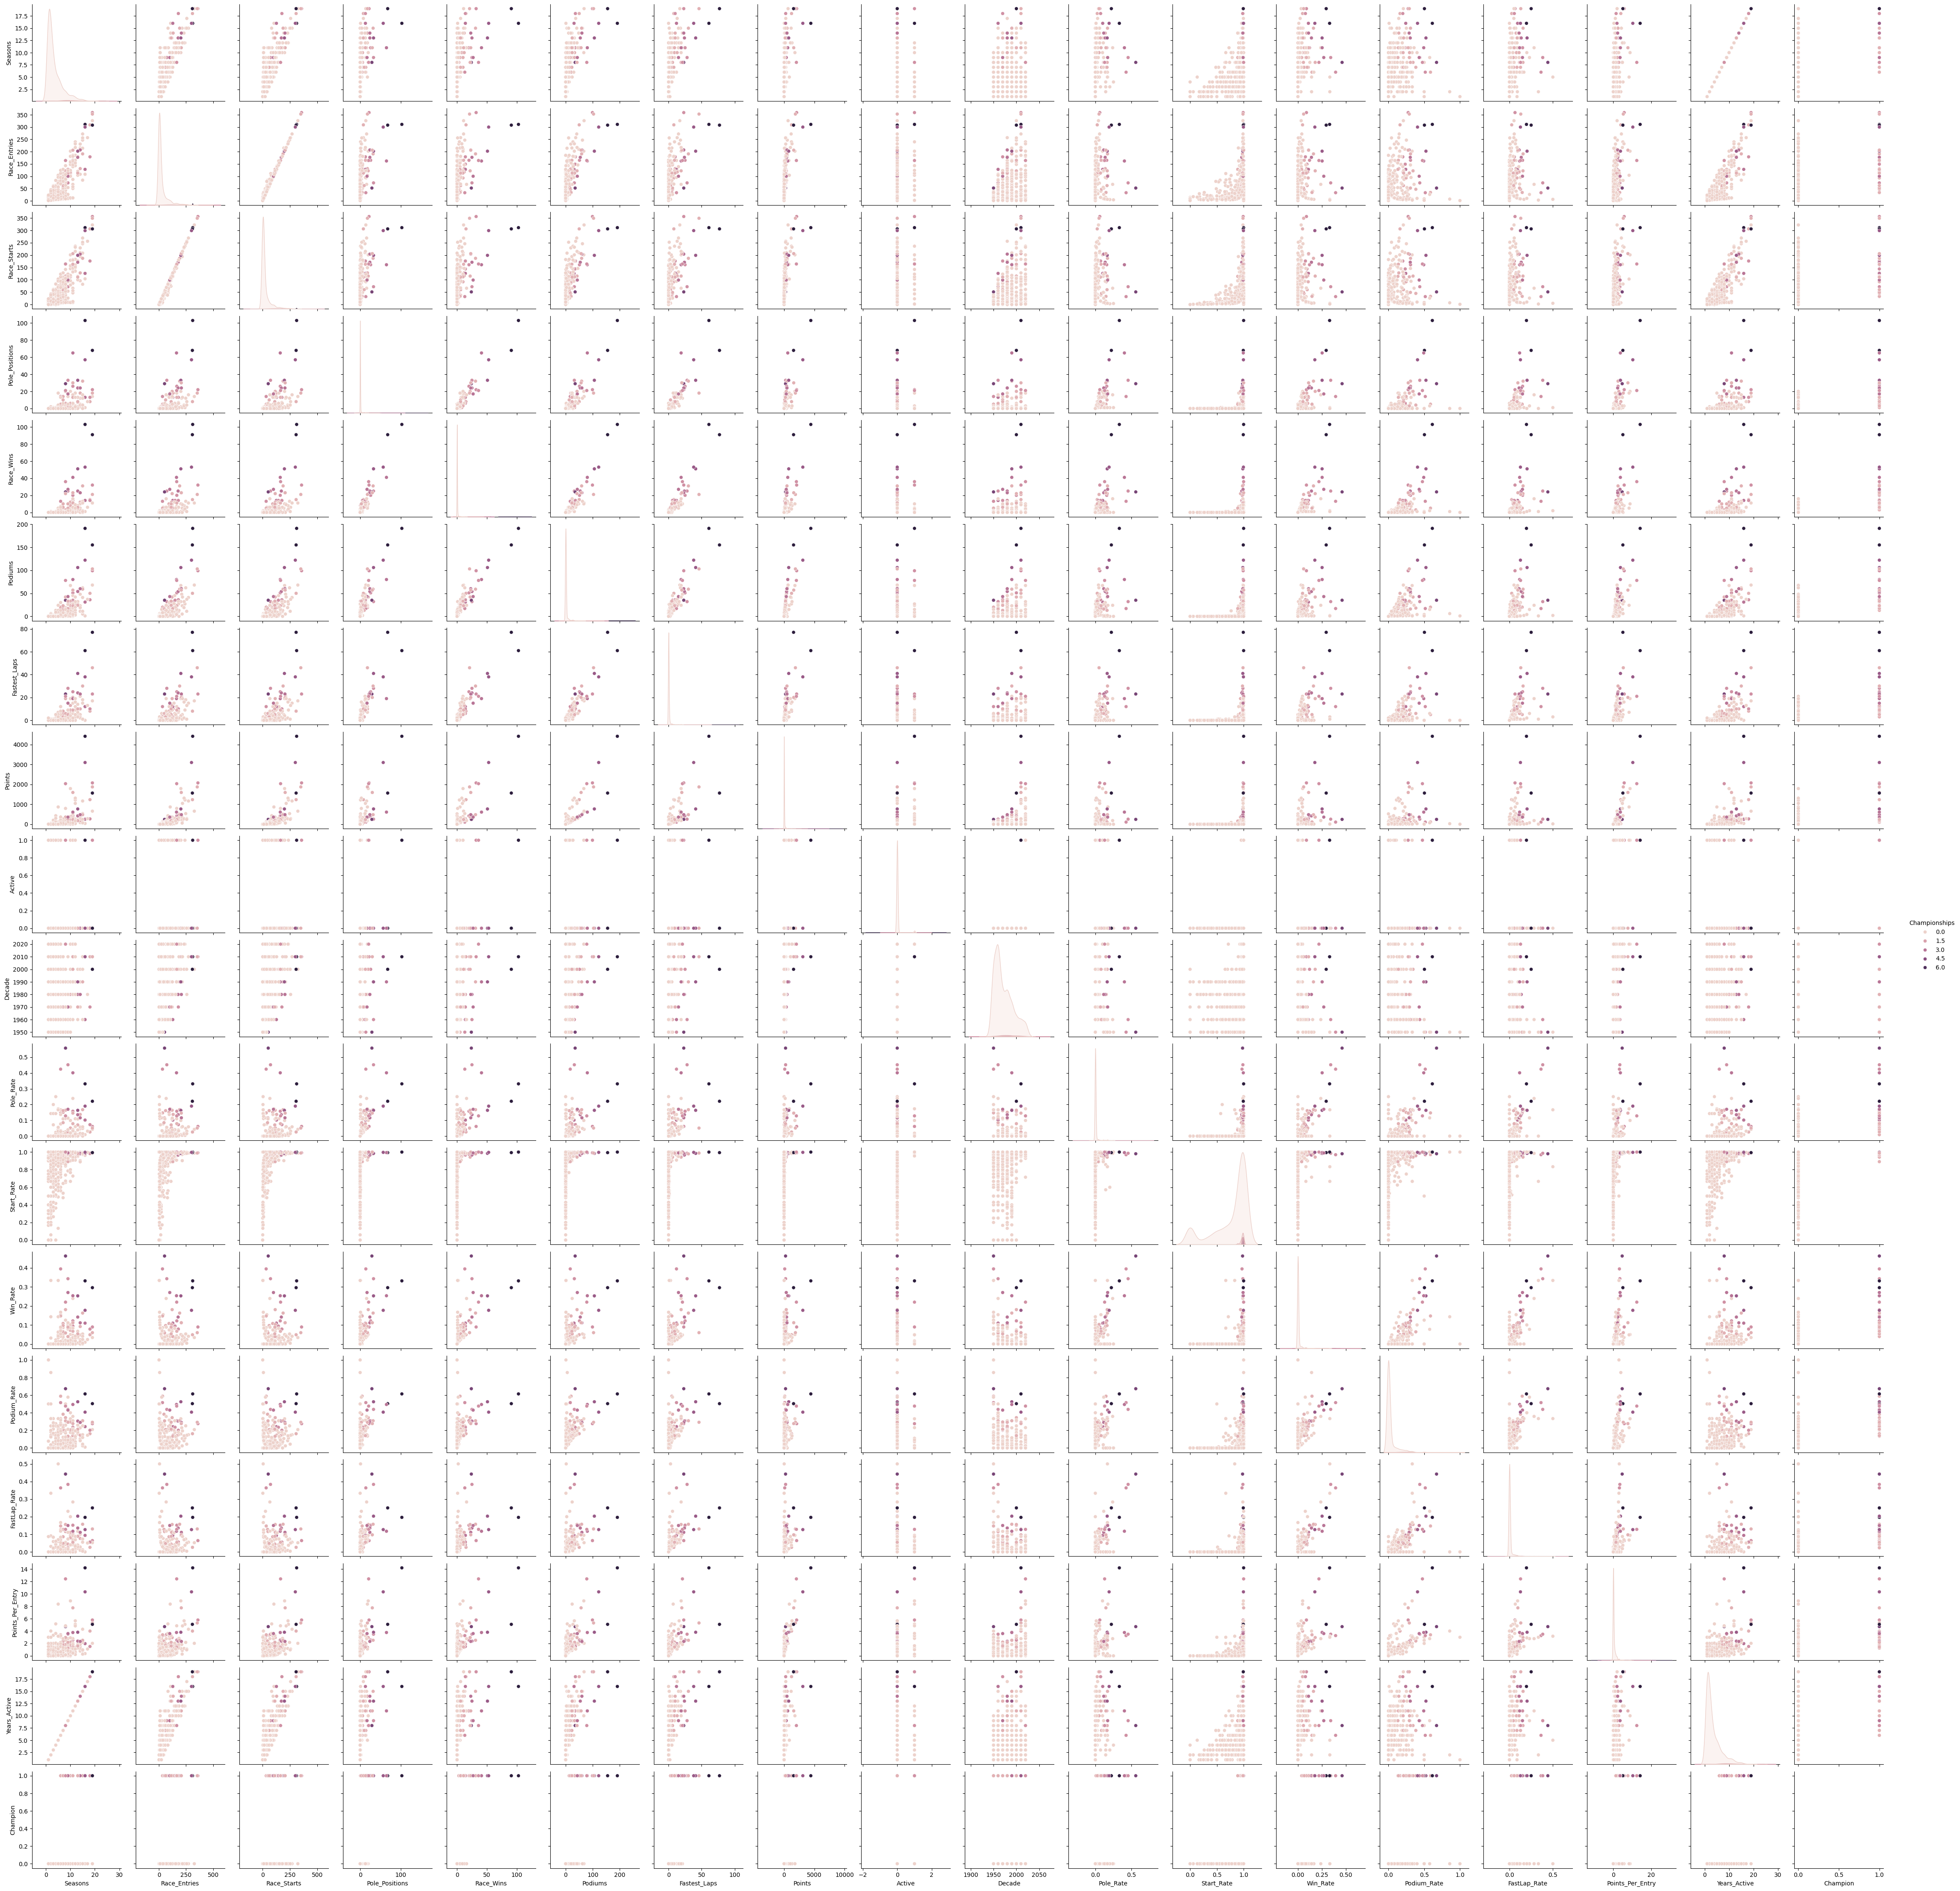

In [ ]:
sns.pairplot(df, hue='Championships')
plt.show()


# **SELECTION FEATURES FOR MODELBUILDING**

In [ ]:
selected_features = champ_corr[champ_corr > 0.5].index.tolist()
print("selected features : ",selected_features)
X = df[selected_features]
y = df['Championships']

selected features :  ['Championships', 'Race_Wins', 'Pole_Positions', 'Fastest_Laps', 'Podiums', 'Win_Rate', 'Pole_Rate', 'Points', 'Points_Per_Entry', 'FastLap_Rate', 'Podium_Rate']


In [ ]:
X = df[['Race_Wins','Pole_Positions','Fastest_Laps','Podiums',
        'Win_Rate','Pole_Rate','Points','Points_Per_Entry',
        'FastLap_Rate','Podium_Rate','Race_Starts']]  # example 11 features
y = df['Championships']



In [ ]:
# Convert to binary: Champion (1) vs Non-Champion (0)
y = df['Championships'].apply(lambda x: 1 if x > 0 else 0)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,stratify=y, random_state=42)



# **FEATURE SCALING**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Now, use X_train_scaled and X_test_scaled for model training and prediction.

In [ ]:
y_test

,Championships
34,0
22,0
207,0
518,0
749,0
...,...
566,0
355,0
731,0
580,0


# USING KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Predict on test data
y_pred = knn.predict(X_test_scaled)

# Evaluate
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
knn_acc = accuracy_score(y_test, y_pred)

[[167   0]
 [  2   5]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       167
           1       1.00      0.71      0.83         7

    accuracy                           0.99       174
   macro avg       0.99      0.86      0.91       174
weighted avg       0.99      0.99      0.99       174



# USING LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg.fit(X_train_scaled, y_train)

# Predict
y_pred_lr = log_reg.predict(X_test_scaled)

# Evaluate
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))
lr_acc = accuracy_score(y_test, y_pred_lr)

[[163   4]
 [  0   7]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       167
           1       0.64      1.00      0.78         7

    accuracy                           0.98       174
   macro avg       0.82      0.99      0.88       174
weighted avg       0.99      0.98      0.98       174



# USING DECISION TREE

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train_scaled, y_train)

# Prediction
y_pred_dt = dt_model.predict(X_test_scaled)

# Accuracy
dt_acc = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", dt_acc)

# Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# Classification Report
print("Classification Report:\n", classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9885057471264368
Confusion Matrix:
 [[166   1]
 [  1   6]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       167
           1       0.86      0.86      0.86         7

    accuracy                           0.99       174
   macro avg       0.93      0.93      0.93       174
weighted avg       0.99      0.99      0.99       174



# USING RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
#Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
#Classification Report
print("Classification Report:",classification_report(y_test,y_pred_rf))

rf_acc = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", rf_acc)

Confusion Matrix:
 [[166   1]
 [  1   6]]
Classification Report:               precision    recall  f1-score   support

           0       0.99      1.00      1.00       167
           1       1.00      0.86      0.92         7

    accuracy                           0.99       174
   macro avg       1.00      0.93      0.96       174
weighted avg       0.99      0.99      0.99       174

Random Forest Accuracy: 0.9942528735632183


# ACCURACY GRAPH

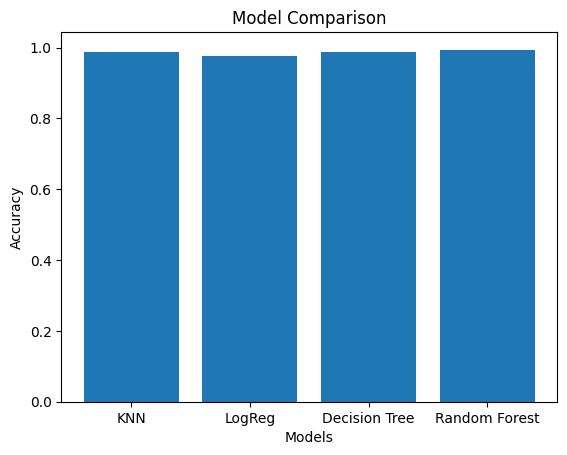

In [ ]:
models = ['KNN', 'LogReg', 'Decision Tree', 'Random Forest']
accuracies = [knn_acc, lr_acc, dt_acc, rf_acc]

import matplotlib.pyplot as plt
plt.bar(models, accuracies)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Comparison")
plt.show()

# FINAL OUTPUT

In [ ]:
new_driver_data = [[10, 25, 5, 300, 0.45, 0.30, 0.20, 0.10, 0.05, 0.02, 0.01]]
feature_names = ['Race_Wins', 'Pole_Positions', 'Fastest_Laps', 'Podiums', 'Win_Rate', 'Pole_Rate', 'Points', 'Points_Per_Entry', 'FastLap_Rate', 'Podium_Rate', 'Race_Starts']

# Create a DataFrame for the new driver data to match the training data format
new_driver_df = pd.DataFrame(new_driver_data, columns=feature_names)

# Scale the new driver data using the *same* scaler fitted on the training data
new_driver_scaled = scaler.transform(new_driver_df)

print("Prediction for New Driver:")

# Using Logistic Regression
prediction_lr = log_reg.predict(new_driver_scaled)
print(f"Logistic Regression: {'Champion' if prediction_lr[0] == 1 else 'Non-Champion'}")

# Using KNN
prediction_knn = knn.predict(new_driver_scaled)
print(f"KNN: {'Champion' if prediction_knn[0] == 1 else 'Non-Champion'}")

# Using Decision Tree
prediction_dt = dt_model.predict(new_driver_scaled)
print(f"Decision Tree: {'Champion' if prediction_dt[0] == 1 else 'Non-Champion'}")

# Using Random Forest
prediction_rf = rf_model.predict(new_driver_scaled)
print(f"Random Forest: {'Champion' if prediction_rf[0] == 1 else 'Non-Champion'}")

Prediction for New Driver:
Logistic Regression: Champion
KNN: Champion
Decision Tree: Non-Champion
Random Forest: Champion
